In [1]:
# %matplotlib inline
%matplotlib widget

In [2]:
import datetime
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import pandas_ta  as ta

In [3]:
import mplfinance as mpf

In [3]:
df = pd.read_csv('d:/xmm.csv', header=None, names=['price', 'maxm1', 'minm1', 'maxm30', 'minm30', 'maxh4', 'minh4'])

In [10]:
df

,price,maxm1,minm1,maxm30,minm30,maxh4,minh4
0,1.12135,1.12185,1.12145,1.11751,1.11534,1.11542,1.10336
1,1.12135,1.12185,1.12145,1.11751,1.11534,1.11542,1.10336
2,1.12135,1.12185,1.12145,1.11751,1.11534,1.11542,1.10336
3,1.12136,1.12185,1.12145,1.11751,1.11534,1.11542,1.10336
4,1.12135,1.12185,1.12145,1.11751,1.11534,1.11542,1.10336
...,...,...,...,...,...,...,...
75469,1.11598,1.11726,1.11396,1.13046,1.11762,1.11886,1.10302
75470,1.11592,1.11726,1.11396,1.13046,1.11762,1.11886,1.10302
75471,1.11570,1.11726,1.11396,1.13046,1.11762,1.11886,1.10302
75472,1.11594,1.11726,1.11396,1.13046,1.11762,1.11886,1.10302


<Axes: >

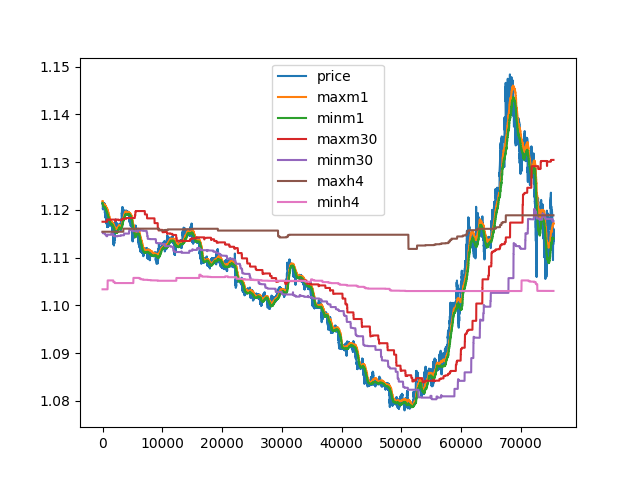

In [11]:
df.plot()

In [3]:
df = pd.read_csv('d:/xmm1.csv', header=None, names=['date', 'price', 'gm1', 'gm30', 'gh4'])

In [4]:
df['datetime'] = pd.to_datetime(df['date'], format='%Y.%m.%d %H:%M')

In [5]:
# df = df.set_index(df['datetime'])

In [6]:
df

,date,price,gm1,gm30,gh4,datetime
0,2020.01.02 06:01,1.12135,-0.00047,-0.00019,0.00051,2020-01-02 06:01:00
1,2020.01.02 06:02,1.12135,-0.00047,-0.00019,0.00051,2020-01-02 06:02:00
2,2020.01.02 06:03,1.12135,-0.00047,-0.00019,0.00051,2020-01-02 06:03:00
3,2020.01.02 06:04,1.12136,-0.00047,-0.00019,0.00051,2020-01-02 06:04:00
4,2020.01.02 06:05,1.12135,-0.00047,-0.00019,0.00051,2020-01-02 06:05:00
...,...,...,...,...,...,...
74869,2020.03.16 08:17,1.11375,0.00016,0.00013,-0.00158,2020-03-16 08:17:00
74870,2020.03.16 08:18,1.11378,0.00016,0.00013,-0.00158,2020-03-16 08:18:00
74871,2020.03.16 08:19,1.11405,0.00014,0.00013,-0.00158,2020-03-16 08:19:00
74872,2020.03.16 08:20,1.11410,0.00014,0.00013,-0.00158,2020-03-16 08:20:00


In [7]:
def make_local_ticks_and_labels_skip_no_data(data_frame_new):
    label_count = len(data_frame_new)
    tick_count = label_count // 5
    
    tick_labels = []
    ticks = []
    ticks.append(data_frame_new.index[0])
    tick_labels.append(data_frame_new['datetime'][0].strftime('%Y-%m-%d %H:%M'))
    for i in range(4):
        ticks.append(data_frame_new.index[tick_count*(i+1)])
        tick_labels.append(data_frame_new['datetime'][tick_count*(i+1)].strftime('%Y-%m-%d %H:%M'))
    tick_labels.append(data_frame_new['datetime'][label_count-1].strftime('%Y-%m-%d %H:%M'))
    ticks.append(data_frame_new.index[label_count-1])
    
    return ticks, tick_labels


In [8]:
# df = df.asfreq(freq='60s', method="bfill")
# df = df.asfreq(freq='60s', method='pad')
# df = df.asfreq('B')

In [9]:
ticks, tick_labels = make_local_ticks_and_labels_skip_no_data(df)

In [10]:
df

,date,price,gm1,gm30,gh4,datetime
0,2020.01.02 06:01,1.12135,-0.00047,-0.00019,0.00051,2020-01-02 06:01:00
1,2020.01.02 06:02,1.12135,-0.00047,-0.00019,0.00051,2020-01-02 06:02:00
2,2020.01.02 06:03,1.12135,-0.00047,-0.00019,0.00051,2020-01-02 06:03:00
3,2020.01.02 06:04,1.12136,-0.00047,-0.00019,0.00051,2020-01-02 06:04:00
4,2020.01.02 06:05,1.12135,-0.00047,-0.00019,0.00051,2020-01-02 06:05:00
...,...,...,...,...,...,...
74869,2020.03.16 08:17,1.11375,0.00016,0.00013,-0.00158,2020-03-16 08:17:00
74870,2020.03.16 08:18,1.11378,0.00016,0.00013,-0.00158,2020-03-16 08:18:00
74871,2020.03.16 08:19,1.11405,0.00014,0.00013,-0.00158,2020-03-16 08:19:00
74872,2020.03.16 08:20,1.11410,0.00014,0.00013,-0.00158,2020-03-16 08:20:00


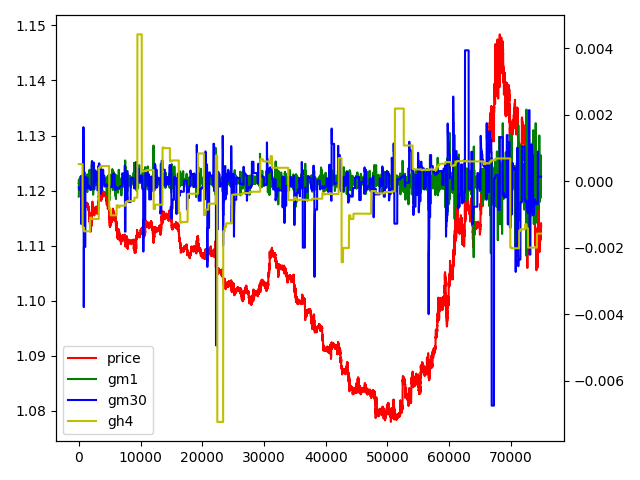

In [7]:
fig, ax1 = plt.subplots()

ax1.plot(df.price, label='price', color='r')
# ax1.xticks(ticks=ticks, labels=tick_labels)

ax2 = ax1.twinx()
ax2.plot(df.gm1, color='g', label='gm1')
ax2.plot(df.gm30, color='b', label='gm30')
ax2.plot(df.gh4, color='y', label='gh4')
# plt.xticks(ticks=ticks, labels=tick_labels)
# plt.xticks(ticks=df.datetime)

lines, labels = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(lines + lines2, labels + labels2, loc=0)

fig.tight_layout()
plt.show()

In [15]:
df.iloc[22410:22500].head(10)

,date,price,gm1,gm30,gh4,datetime
22410,2020.01.23 19:56,1.10513,0.00002,-0.00145,0.00077,2020-01-23 19:56:00
22411,2020.01.23 19:57,1.10510,0.00002,-0.00145,0.00077,2020-01-23 19:57:00
22412,2020.01.23 19:58,1.10517,0.00002,-0.00145,0.00077,2020-01-23 19:58:00
22413,2020.01.23 19:59,1.10517,0.00002,-0.00145,0.00077,2020-01-23 19:59:00
22414,2020.01.23 20:00,1.10511,0.00002,-0.00145,0.00077,2020-01-23 20:00:00
22415,2020.01.23 20:01,1.10517,0.00002,-0.00145,-0.00724,2020-01-23 20:01:00
22416,2020.01.23 20:02,1.10519,0.00002,-0.00145,-0.00724,2020-01-23 20:02:00
22417,2020.01.23 20:03,1.10506,0.00002,-0.00145,-0.00724,2020-01-23 20:03:00
22418,2020.01.23 20:04,1.10494,-0.00019,-0.00145,-0.00724,2020-01-23 20:04:00
22419,2020.01.23 20:05,1.10488,-0.00014,-0.00145,-0.00724,2020-01-23 20:05:00


In [3]:
#################################################

In [43]:
df = pd.read_csv('d:/xmmM1.csv', header=None, names=['date', 'open', 'high', 'low', 'close', 'maxmin', 'max', 'min'])

In [44]:
df['datetime'] = pd.to_datetime(df['date'], format='%Y.%m.%d %H:%M')

In [45]:
df['ma60'] = df.ta.sma(60)

In [46]:
# df = df.groupby('datetime', as_index=False).last()

In [47]:
df = df.set_index('datetime')

In [48]:
df.replace(0, np.nan, inplace=True)

In [49]:
df.head(5) # df.iloc[50:].head(50) # 

,date,open,high,low,close,maxmin,max,min,ma60
datetime,,,,,,,,,
2019-12-31 21:38:00,2019.12.31 21:38,1.12203,1.12207,1.12203,1.12206,NaN,NaN,NaN,NaN
2019-12-31 21:39:00,2019.12.31 21:39,1.12206,1.12206,1.12201,1.12201,NaN,NaN,NaN,NaN
2019-12-31 21:40:00,2019.12.31 21:40,1.12198,1.12199,1.12193,1.12193,NaN,NaN,NaN,NaN
2019-12-31 21:41:00,2019.12.31 21:41,1.12192,1.12192,1.12190,1.12190,NaN,NaN,NaN,NaN
2019-12-31 21:42:00,2019.12.31 21:42,1.12190,1.12191,1.12190,1.12190,NaN,NaN,NaN,NaN


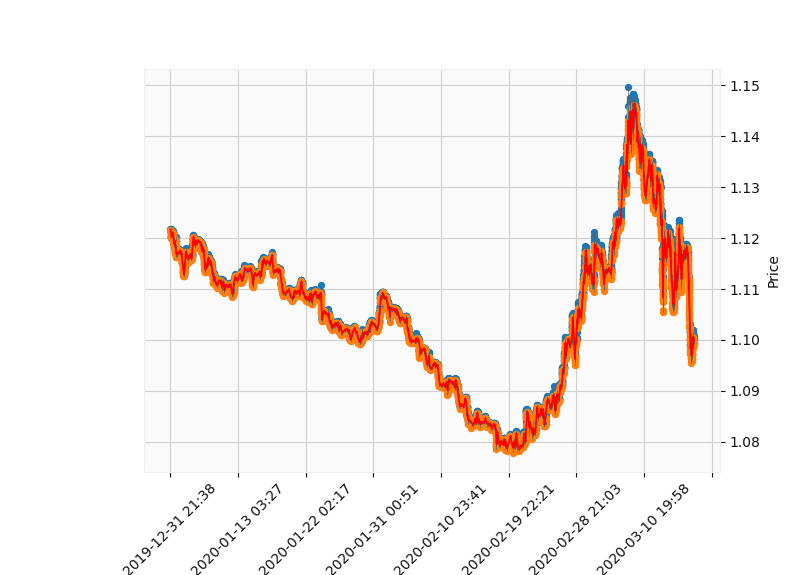

In [50]:
apds = [
    # mpf.make_addplot(data=df['maxmin'], secondary_y=False, type='scatter'),
    mpf.make_addplot(data=df['ma60'], secondary_y=False, type='line', color='r'),
    mpf.make_addplot(data=df[['max', 'min']], secondary_y=False, type='scatter'),
       ]
mpf.plot(df, addplot=apds, type='candle', warn_too_much_data=df.shape[0], style='yahoo', datetime_format='%Y-%m-%d %H:%M') # returnfig=True

In [49]:
dfM1 = pd.read_csv('d:/xmmM1.csv', header=None, names=['date', 'open', 'high', 'low', 'close', 'maxmin', 'max', 'min'])
dfM30 = pd.read_csv('d:/xmmM30.csv', header=None, names=['date', 'open', 'high', 'low', 'close', 'maxmin', 'max', 'min'])
dfH4 = pd.read_csv('d:/xmmH4.csv', header=None, names=['date', 'open', 'high', 'low', 'close', 'maxmin', 'max', 'min'])

In [50]:
dfM1['datetime'] = pd.to_datetime(dfM1['date'], format='%Y.%m.%d %H:%M')
dfM30['datetime'] = pd.to_datetime(dfM30['date'], format='%Y.%m.%d %H:%M')
dfH4['datetime'] = pd.to_datetime(dfH4['date'], format='%Y.%m.%d %H:%M')

In [51]:
dfM1['ma30'] = dfM1.ta.sma(30)
dfM30['ma30'] = dfM30.ta.sma(30)
dfH4['ma30'] = dfH4.ta.sma(30)

dfM1['ma60'] = dfM1.ta.sma(60)
dfM30['ma60'] = dfM30.ta.sma(60)
dfH4['ma60'] = dfH4.ta.sma(60)

In [52]:
dfM1 = dfM1.set_index('datetime')
dfM30 = dfM30.set_index('datetime')
dfH4 = dfH4.set_index('datetime')

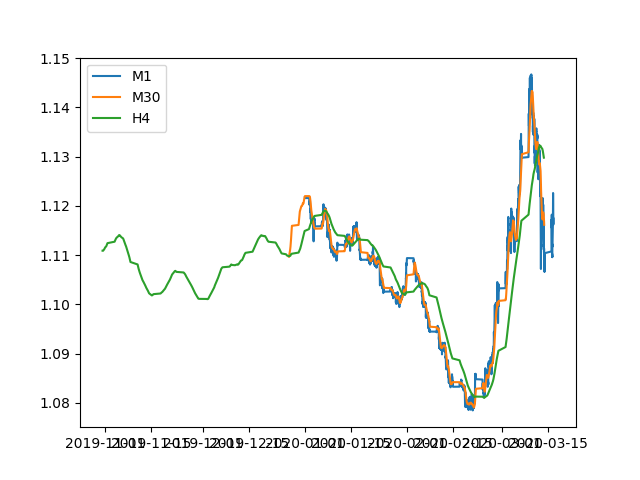

In [61]:
plt.plot(dfM1.ma30, label='M1')
plt.plot(dfM30.ma30, label='M30')
plt.plot(dfH4.ma30, label='H4')
plt.legend()
plt.show()

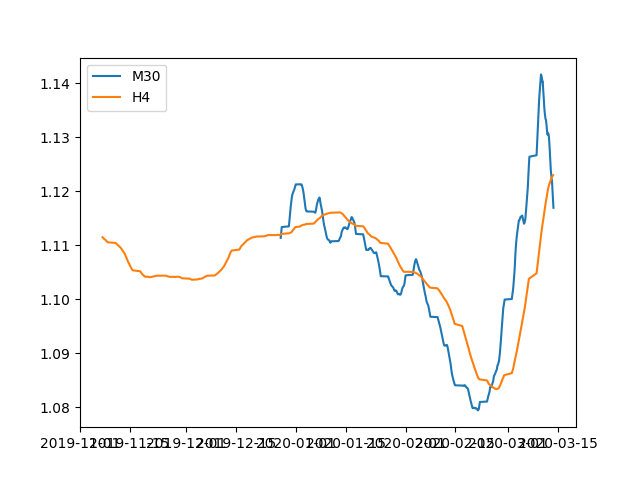

In [63]:
# plt.plot(dfM1.ma60, label='M1')
plt.plot(dfM30.ma60, label='M30')
plt.plot(dfH4.ma60, label='H4')
plt.legend()
plt.show()

In [62]:
plt.close()

In [28]:
# plt.plot?